# 02 — Sélection de points : l'arbre des bassins

Amont d'Espinasses (Durance, juste en aval du barrage de Serre-Ponçon) : stations, carte, arbre.

In [1]:
%matplotlib inline
import time
import pandas as pd
import pyogrio
import requests
import folium
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

import sys
from pathlib import Path

_racine = Path.cwd()
while not (_racine / "src").exists() and _racine != _racine.parent:
    _racine = _racine.parent
if str(_racine) not in sys.path:
    sys.path.insert(0, str(_racine))

from src import config
from src.bassins import Reseau, bassins_amont_du_point, localiser, voronoi_meteo_amont, recouvrement, carreaux_amont

## 1. Réseau

Les 1,03 million de bassins du monde et leur arbre.

In [2]:
R = Reseau()
print(f"{len(R.bassins):,} bassins | {len(R.foret.racines):,} racines")

1,034,083 bassins | 63,523 racines


## 2. Stations réelles (Hub'Eau), actives, vraiment dans le bassin

Élargi jusqu'à Espinasses [QNR Serre-Ponçon] (pas de station Hub'Eau exactement « à Talard » --
vérifié par nom et par commune, aucune) : le point de contrôle juste après le barrage/lac.
Ça inclut au passage tout l'Ubaye, qui se jette dans le lac.

In [4]:
LON_REF, LAT_REF = 6.272764047, 44.470913176   # Espinasses [QNR Serre-Ponçon] (Hub'Eau)
amont = bassins_amont_du_point(LON_REF, LAT_REF, R.foret, bassins=R.bassins).index
print(f"{len(amont)} bassins en amont d'Espinasses")

r = requests.get("https://hubeau.eaufrance.fr/api/v2/hydrometrie/referentiel/stations", params={
    "bbox": "5.9,44.2,6.9,45.1", "en_service": "true", "size": 1000, "format": "json",
}, timeout=30).json()
candidats = pd.DataFrame(r["data"])
candidats = candidats[candidats.type_station == "STD"][
    ["code_station", "libelle_station", "libelle_cours_eau", "longitude_station", "latitude_station"]
].dropna(subset=["longitude_station", "latitude_station"])

b = localiser(candidats.longitude_station.to_numpy(), candidats.latitude_station.to_numpy())
candidats["bassin"] = b
STATIONS = candidats[
    candidats.bassin.notna() & candidats.bassin.astype("float64").isin(amont.astype(float))
].rename(columns={"code_station": "code", "libelle_station": "nom",
                   "longitude_station": "lon", "latitude_station": "lat"}).reset_index(drop=True)

# surface officielle (référentiel des sites) pour chaque station trouvée
surfaces = []
for code in STATIONS["code"]:
    rs = requests.get("https://hubeau.eaufrance.fr/api/v2/hydrometrie/referentiel/sites",
                       params={"code_site": code[:8], "format": "json"}, timeout=60).json()
    d = rs.get("data", [])
    surfaces.append(d[0].get("surface_bv") if d else None)
STATIONS["surface_bv_km2"] = surfaces

print(f"{len(STATIONS)} stations actives trouvées, sur {STATIONS.libelle_cours_eau.nunique()} cours d'eau différents")
STATIONS[["code", "nom", "libelle_cours_eau", "surface_bv_km2"]]

27 bassins en amont d'Espinasses
13 stations actives trouvées, sur 5 cours d'eau différents


,code,nom,libelle_cours_eau,surface_bv_km2
0,X001001002,La Durance à Val-des-Prés [Les Alberts],La Durance,214.13
1,X001501002,La Guisane au Monêtier-les-Bains [Le Casset] -...,La Guisane,90.15
2,X001561301,La Durance à Briançon [aval] - aval - Station ...,La Durance,548.00
3,X013001001,La Durance à l'Argentière-la-Bessée,La Durance,962.53
4,X023000202,Le Guil à Château-Ville-Vieille [Pont de la Ch...,Le Guil,420.00
5,X031001001,La Durance à Embrun [La Clapière],La Durance,2174.81
6,X031001002,La Durance à Embrun [La Clapière] - EDF,La Durance,2174.81
7,X041541001,Le Riou Mounal à Saint-Paul-sur-Ubaye [Col de ...,Riou Mounal,3.00
8,X043401001,L'Ubaye à Barcelonnette [Abattoir],L'Ubaye,542.66
9,X045401001,L'Ubaye au Lauzet-Ubaye [Roche-Rousse],L'Ubaye,942.96


Rattache chaque station à son bassin ; écart relatif entre la surface amont du bassin trouvé et la surface officielle Hub'Eau.

In [6]:
hors = R.ajouter_stations(STATIONS, code="code", surface_km2="surface_bv_km2")
print("stations hors de tout bassin :", hors)
R.stations[["surface_officielle_km2", "surface_amont_bassin_km2", "ecart_surface"]]

stations hors de tout bassin : 0


,surface_officielle_km2,surface_amont_bassin_km2,ecart_surface
code,,,
X001001002,214.13,222.2,0.037687
X001501002,90.15,197.4,1.189684
X001561301,548.00,652.9,0.191423
X013001001,962.53,996.2,0.034981
X023000202,420.00,448.3,0.067381
X031001001,2174.81,2272.6,0.044965
X031001002,2174.81,2272.6,0.044965
X041541001,3.00,201.9,66.300000
X043401001,542.66,556.2,0.024951


## 3. Carte

Fond de relief (OpenTopoMap), une seule carte à couches à cocher.

In [7]:
polys_amont = pyogrio.read_dataframe(config.GDB_BASSINS, layer=config.COUCHE_NIVEAU_12,
                                      columns=["HYBAS_ID"], bbox=(5.9, 44.2, 6.9, 45.1))
polys_amont = polys_amont.set_index("HYBAS_ID").loc[amont]
centroides = polys_amont["geometry"].apply(lambda g: g.representative_point())
len(polys_amont)

27

In [8]:
def fond_relief(polys):
    carte = folium.Map(tiles=None)
    folium.TileLayer(
        tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
        attr="OpenTopoMap (CC-BY-SA), données SRTM/OSM",
        name="Fond : relief (OpenTopoMap)", max_zoom=17, overlay=True, control=True,
    ).add_to(carte)
    x0, y0, x1, y1 = polys.total_bounds
    carte.fit_bounds([[y0, x0], [y1, x1]])
    # le conteneur n'a pas toujours sa taille finale au premier rendu (Jupyter/VS Code) ->
    # la carte s'affiche dézoomée sur le monde entier tant qu'on ne la retouche pas ;
    # on force un recalcul + un re-cadrage juste après le premier rendu.
    carte.get_root().script.add_child(folium.Element(
        f"""setTimeout(function() {{
            {carte.get_name()}.invalidateSize();
            {carte.get_name()}.fitBounds([[{y0}, {x0}], [{y1}, {x1}]]);
        }}, 250);"""
    ))
    return carte


Au survol d'un bassin : surface, altitude min/moy/max, débit moyen sortant (modélisé par ATLAS, cumulé : tout l'amont compris), débit spécifique (débit / surface amont totale), ruissellement local (eau produite dans ce bassin seul), couverture neigeuse, précipitation moyenne, degré de régulation (barrages), surface glaciaire.

Couches météo (décochées par défaut) : pavage de Voronoï des carreaux Open-Meteo (`voronoi_meteo_amont`) -- au survol, la part de l'amont servie par chaque carreau -- et leurs centres. Centres calculés, 0 appel à Open-Meteo.

In [9]:
polys_amont2 = polys_amont.copy()
champs = ["SUB_AREA", "UP_AREA", "ele_mt_smn", "ele_mt_sav", "ele_mt_smx",
          "dis_m3_pyr", "run_mm_syr", "snw_pc_syr", "pre_mm_syr", "dor_pc_pva", "gla_pc_sse"]
for c in champs:
    polys_amont2[c] = R.bassins.loc[amont, c]
polys_amont2["dis_m3_pyr"] = polys_amont2["dis_m3_pyr"].astype("float64").round(2)
polys_amont2["SUB_AREA"] = polys_amont2["SUB_AREA"].round(1)
polys_amont2["debit_specifique_L_s_km2"] = (polys_amont2["dis_m3_pyr"] * 1000 / polys_amont2["UP_AREA"]).round(1)

carte = fond_relief(polys_amont2)

folium.GeoJson(
    polys_amont2.reset_index().to_json(), name="Bassins amont",
    style_function=lambda f: {"fillColor": "#1f77b4", "color": "#0d47a1", "weight": 2, "fillOpacity": 0.15},
    tooltip=folium.GeoJsonTooltip(
        fields=["HYBAS_ID", "SUB_AREA", "ele_mt_smn", "ele_mt_sav", "ele_mt_smx", "dis_m3_pyr",
                "debit_specifique_L_s_km2", "run_mm_syr", "snw_pc_syr", "pre_mm_syr",
                "dor_pc_pva", "gla_pc_sse"],
        aliases=["Bassin", "Surface (km²)", "Altitude min (m)", "Altitude moy. (m)", "Altitude max (m)",
                 "Débit moyen sortant, cumulé (m³/s)", "Débit spécifique (L/s/km² amont)",
                 "Ruissellement local (mm/an)", "Neige, couverture moy. (%)", "Précipitation moy. (mm/an)",
                 "Degré de régulation (%)", "Surface glaciaire (%)"]),
).add_to(carte)

couche_stations = folium.FeatureGroup(name="Stations").add_to(carte)
for code, s in R.stations.iterrows():
    folium.Marker([s["lat"], s["lon"]], icon=folium.Icon(color="red", icon="tint"),
                  popup=f"{code} — écart de surface {s['ecart_surface']:+.1%}").add_to(couche_stations)

couche_baryc = folium.FeatureGroup(name="Barycentres des bassins", show=False).add_to(carte)
for h, p in centroides.items():
    folium.CircleMarker([p.y, p.x], radius=5, color="#0d3", fill=True, fill_opacity=0.9,
                         tooltip=str(h)).add_to(couche_baryc)

pavage = voronoi_meteo_amont(int(localiser([LON_REF], [LAT_REF])[0]), R.foret)
pmax = pavage.pourcentage.max()
folium.GeoJson(
    pavage.round({"lon_centre": 4, "lat_centre": 4, "surface_km2": 1, "pourcentage": 2}).to_json(),
    name=f"Pavage de Voronoï météo ({len(pavage)} carreaux)", show=False,
    style_function=lambda f: {"fillColor": "#e07a1f", "color": "#7a3d00", "weight": 1.2,
                              "fillOpacity": 0.1 + 0.5 * f["properties"]["pourcentage"] / pmax},
    tooltip=folium.GeoJsonTooltip(fields=["pourcentage", "surface_km2", "lat_centre", "lon_centre"],
                                  aliases=["Part de l'amont (%)", "Surface (km²)", "Latitude du centre", "Longitude du centre"]),
).add_to(carte)
couche_meteo = folium.FeatureGroup(name=f"Centres des carreaux météo ({len(pavage)})", show=False).add_to(carte)
for _, cm in pavage.iterrows():
    folium.CircleMarker([cm.lat_centre, cm.lon_centre], radius=4, color="#a01414", fill=True,
                        fill_opacity=0.9).add_to(couche_meteo)

folium.LayerControl(collapsed=False).add_to(carte)
carte

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


## 4. Arbre de l'amont

Un nœud = un bassin, une flèche = vers le bassin aval. Sources en haut, exutoire (Espinasses) en bas ; carrés rouges = bassins avec une station (code affiché).

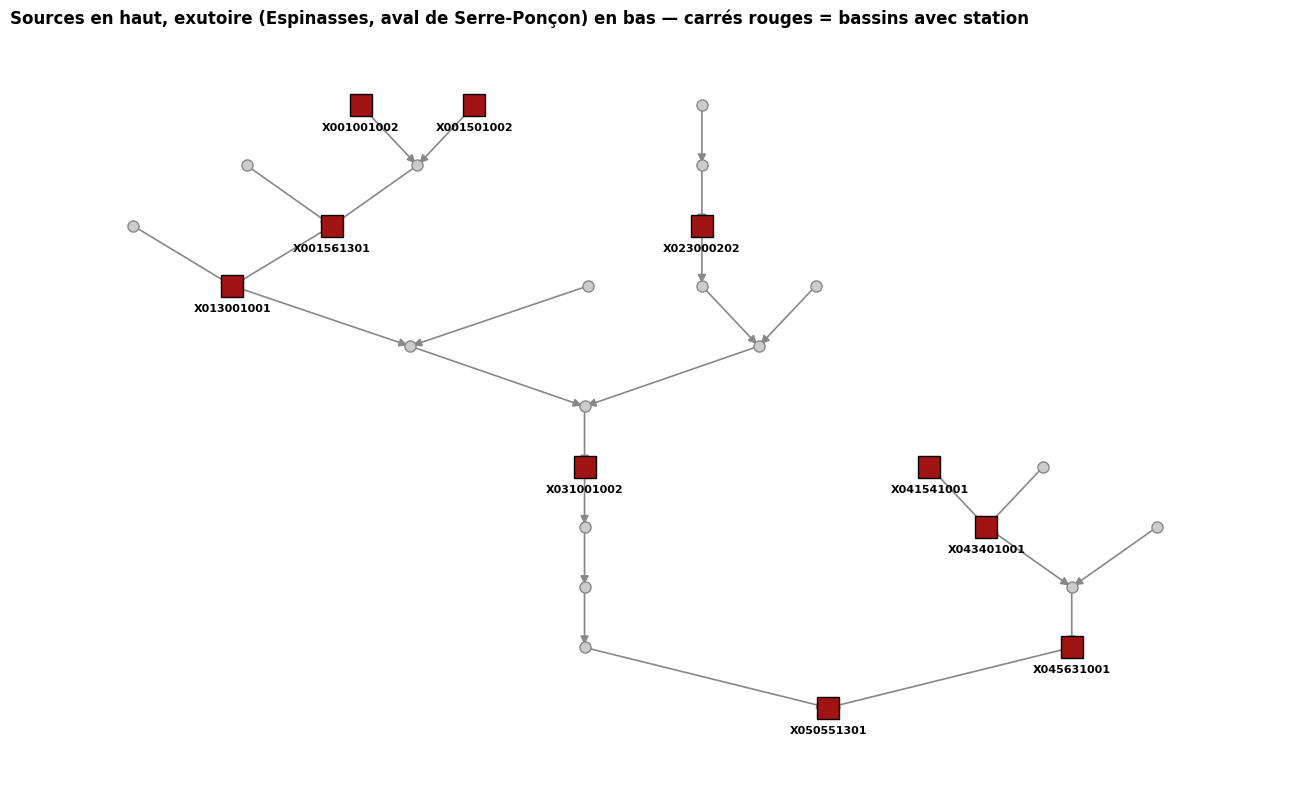

In [8]:
enfants = {h: [c for c in R.foret.affluents(h) if c in amont] for h in amont}
xs = {}
compteur = [0]


def poser(h):
    fils = enfants[h]
    if not fils:
        xs[h] = compteur[0]
        compteur[0] += 1
        return xs[h]
    vals = [poser(f) for f in fils]
    xs[h] = sum(vals) / len(vals)
    return xs[h]


bassin_ref = int(localiser([LON_REF], [LAT_REF])[0])
poser(bassin_ref)
prof = {h: int(R.foret.profondeur[R.foret.indice(h)]) for h in amont}
pos = {h: (xs[h], prof[h]) for h in amont}

code_par_bassin = {int(b): c for c, b in R.stations["bassin"].astype("float64").items()}

fig, ax = plt.subplots(figsize=(13, 8))
for h in amont:
    reste = R.foret.aval(h, inclure=False)
    aval_h = int(reste[0]) if len(reste) else None
    if aval_h is not None and aval_h in pos:
        x1, y1 = pos[h]; x2, y2 = pos[aval_h]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                                      color="#888", lw=1.2, zorder=1))
for h, (x, y) in pos.items():
    if h in code_par_bassin:
        ax.plot(x, y, "s", ms=16, mfc="#a01414", mec="k", zorder=3)
        ax.annotate(code_par_bassin[h], (x, y), xytext=(0, -13), textcoords="offset points",
                    ha="center", va="top", fontsize=8, fontweight="bold")
    else:
        ax.plot(x, y, "o", ms=8, mfc="#ccc", mec="#888", zorder=2)
ax.set_title("Sources en haut, exutoire (Espinasses, aval de Serre-Ponçon) en bas — carrés rouges = bassins avec station",
              fontsize=12, fontweight="bold", loc="left")
ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.margins(0.12)
plt.tight_layout()
plt.show()

## 5. Carreaux météo d'un bassin

Table de recouvrement d'un continent : une ligne par morceau commun à un bassin et un carreau (numéro du carreau, centre, surface). Calculée la première fois (~30 s pour l'Europe), puis relue depuis `data/cache/`. Rangée par bassin. Ci-dessous : le bassin d'Espinasses seul.

In [9]:
t = time.time()
table = recouvrement(2)   # 2 = Europe : 1er chiffre de l'identifiant des bassins
print(f"{len(table):,} lignes, {table.index.nunique():,} bassins ({time.time() - t:.1f} s)")
zone = int(localiser([LON_REF], [LAT_REF])[0])
carreaux_amont(zone, R.foret, amont=False)

865,866 lignes, 137,658 bassins (0.0 s)


,carreau,lon_centre,lat_centre,surface_km2,pourcentage
0,848909,6.211656,44.463971,14.260665,63.006086
1,848910,6.349693,44.463971,5.332465,23.559754
2,846305,6.221198,44.534270,3.040659,13.434159


Tout l'amont : lignes de ses bassins additionnées carreau par carreau.

In [10]:
t = time.time()
carreaux = carreaux_amont(zone, R.foret)
print(f"{len(carreaux)} carreaux, {carreaux.surface_km2.sum():.0f} km² ({1000 * (time.time() - t):.1f} ms)")
ecart = (carreaux.set_index("carreau").pourcentage - pavage.set_index("carreau").pourcentage).abs().max()
print(f"écart max avec le pavage de la carte : {ecart:.4f} %")
carreaux

61 carreaux, 3583 km² (1.3 ms)
écart max avec le pavage de la carte : 0.0003 %


,carreau,lon_centre,lat_centre,surface_km2,pourcentage
0,830767,6.558140,44.956062,86.012142,2.400657
1,833347,6.547988,44.885763,85.991154,2.400071
2,835933,6.816074,44.815465,85.966729,2.399389
3,835932,6.676971,44.815465,85.957155,2.399122
4,835931,6.537867,44.815465,85.945852,2.398807
...,...,...,...,...,...
56,838523,7.083333,44.745166,6.224130,0.173720
57,833350,6.965944,44.885763,2.163473,0.060384
58,856748,6.595420,44.253075,0.165410,0.004617
59,856747,6.458015,44.253075,0.002195,0.000061
